In [1]:
import matplotlib.pyplot  as plt
import pandas as pd
import copy

from pathlib import Path
from pprint import pprint
from eval_util import load_csv_files, visualize_runtime_overhead, calculate_model_performance, print_metrics

In [ ]:
resnet_path = Path("../csv-files/resnet/general")
vgg_path = Path("../csv-files/vgg/general")
diagrams_folder = Path("diagrams")
diagrams_folder.mkdir(parents=True, exist_ok=True)

# Load csv files
resnet_dataframes = load_csv_files(resnet_path)
vgg_dataframes = load_csv_files(vgg_path)

# Create Accuracy Table

In [ ]:
# Average attestation amount and verdict time
print(vgg_path)
verdict_table = {}

for binary_name, df in resnet_dataframes.items():
    df["total_attestation_amount"] = df["amount_good_attestation_results"] + df["amount_bad_attestation_results"]

    df_bad_verdict = df[df["final_attestation_verdict"] == "Bad"]

    verdict_table[binary_name] = {
        "Amount Attestations": df_bad_verdict["total_attestation_amount"].mean(),
        "Final Verdict Time": df_bad_verdict["final_verdict_fn_calls"].mean()
    }

verdict_df = pd.DataFrame.from_dict(verdict_table)
verdict_df = verdict_df[sorted(verdict_df.columns)]

print(verdict_df.to_latex(float_format="%.2f"))
verdict_df.head()

In [ ]:
# Evaluation Metrics 
metrics = calculate_model_performance(vgg_dataframes)
resnet_df = pd.DataFrame.from_dict(metrics)

# Turn numbers into percentage
for column in resnet_df:
    resnet_df[column] = (resnet_df[column] * 100).round(2)

# Rename Rows
for index in resnet_df.index:
    new_index = [x.capitalize() for x in index.split("_")]
    resnet_df = resnet_df.rename(index={index: " ".join(new_index)})

# Sort Columns
resnet_df = resnet_df[sorted(resnet_df.columns)]

print(resnet_df.to_latex(float_format="%.2f"))

resnet_df.head(10)


# Create Memory Impact Plot

In [ ]:
def allowed(path: Path, banned: list[str]) -> bool:
    return not any(b in path.as_posix() for b in banned)

In [ ]:
from pathlib import Path

# Merge binary results into one
binaries_folder = Path("../csv-files/binaries")
csv_file_header = "binary,input_type,input_file_name,snapshot_frequency,amount_good_attestation_results,amount_bad_attestation_results,final_attestation_verdict,final_normal_verdict,runtime_normal,amount_instructions_normal,runtime_attestation,amount_instructions_attestation,average_inference_time,final_verdict_fn_calls,average_memory_size"
rows = []

cpu_resnet_filter = ["import", "memory", "vgg", "gpu", "tch"]
cpu_vgg_filter = ["import", "memory", "resnet", "gpu", "tch"]

gpu_resnet_filter = ["import", "memory", "vgg", "cpu", "tch"]
gpu_vgg_filter = ["import", "memory", "resnet", "cpu", "tch"]

cpu_tch_resnet_filter = ["import", "memory", "vgg"]
cpu_tch_vgg_filter = ["import", "memory", "resnet"]

for file_name in binaries_folder.rglob("*"):
    if file_name.is_dir():
        continue
    
    if not allowed(file_name, cpu_tch_vgg_filter):
        continue

    if "cpu-tch" not in str(file_name):
        continue

    with open(file_name, "r") as f:
        file_content = f.read()
    
    binary_name = str(file_name).split("/")[3]
    row = binary_name + ","
    row += file_content.split("\n")[1]
    rows.append(row)
    # print(file_name)

# Write combined csv file
# with open("../csv-files/cpu-tch-vgg.csv", "w") as f:
#     f.write(csv_file_header + "\n")
#     f.write("\n".join(rows))

Filtered results
Average inference time for the first 10 entries (sorted by memory size): 6.16
Average memory size for the first 10 entries (sorted by memory size): 6724.44
Average inference time for the last 10 entries (sorted by memory size): 40.17
Average memory size for the last 10 entries (sorted by memory size): 8337151.71

All data results
Average inference time for the first 10 entries (sorted by memory size): 6.16
Average memory size for the first 10 entries (sorted by memory size): 6724.44
Average inference time for the last 10 entries (sorted by memory size): 97.14
Average memory size for the last 10 entries (sorted by memory size): 27083843.78


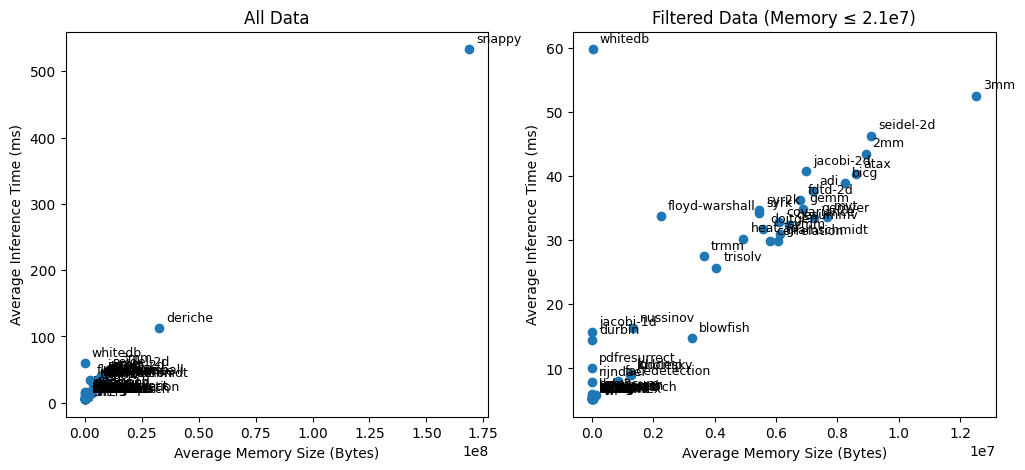

In [23]:
import pandas as pd
import matplotlib.pyplot  as plt
from eval_util import parse_duration_to_ms

# Create scatter plot
binaries_df = pd.read_csv("../csv-files/gpu-vgg.csv", sep=",")
binaries_df["average_inference_time"] = binaries_df["average_inference_time"].apply(parse_duration_to_ms)

# Create figure with 1 row and 2 columns of subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# First plot - all data
ax1.scatter(binaries_df["average_memory_size"], binaries_df["average_inference_time"])
ax1.set_xlabel("Average Memory Size (Bytes)")
ax1.set_ylabel("Average Inference Time (ms)")
ax1.set_title("All Data")

# Second plot - filtered data
df_filtered = binaries_df[binaries_df["average_memory_size"] <= 2.1e7]
ax2.scatter(df_filtered["average_memory_size"], df_filtered["average_inference_time"])
ax2.set_xlabel("Average Memory Size (Bytes)")
ax2.set_ylabel("Average Inference Time (ms)")
ax2.set_title("Filtered Data (Memory ≤ 2.1e7)")

# Add binary names
for _, row in binaries_df.iterrows():
    ax1.annotate(
        row['binary'],
        (row['average_memory_size'], row['average_inference_time']),
        textcoords="offset points",
        xytext=(5, 5),
        ha='left',
        fontsize=9
    )

for _, row in binaries_df.iterrows():
    ax2.annotate(
        row['binary'],
        (row['average_memory_size'], row['average_inference_time']),
        textcoords="offset points",
        xytext=(5, 5),
        ha='left',
        fontsize=9
    )

# # Save Plot
# diagrams_folder = Path("diagrams")
# diagrams_folder.mkdir(parents=True, exist_ok=True)

# plt.savefig(diagrams_folder/"memory-impact-cpu-tch-vgg.pdf", bbox_inches='tight', dpi=300)

# # Adjust layout to prevent overlap
# plt.tight_layout()
# plt.show()




# Average runtime increase
print("Filtered results")
df_sorted = df_filtered.sort_values("average_memory_size")
print(f"Average inference time for the first 10 entries (sorted by memory size): {(df_sorted.head(10)["average_inference_time"].mean()):.2f}")
print(f"Average memory size for the first 10 entries (sorted by memory size): {(df_sorted.head(10)["average_memory_size"].mean()):.2f}")

print(f"Average inference time for the last 10 entries (sorted by memory size): {(df_sorted.tail(10)["average_inference_time"].mean()):.2f}")
print(f"Average memory size for the last 10 entries (sorted by memory size): {(df_sorted.tail(10)["average_memory_size"].mean()):.2f}")

print("\nAll data results")
df_sorted = binaries_df.sort_values("average_memory_size")
print(f"Average inference time for the first 10 entries (sorted by memory size): {(df_sorted.head(10)["average_inference_time"].mean()):.2f}")
print(f"Average memory size for the first 10 entries (sorted by memory size): {(df_sorted.head(10)["average_memory_size"].mean()):.2f}")

print(f"Average inference time for the last 10 entries (sorted by memory size): {(df_sorted.tail(10)["average_inference_time"].mean()):.2f}")
print(f"Average memory size for the last 10 entries (sorted by memory size): {(df_sorted.tail(10)["average_memory_size"].mean()):.2f}")


# Attestation Overhead

In [2]:
import json

binaries_folder = Path("../csv-files/binaries")
run_modes = ["cpu", "cpu-tch", "gpu"]
instr_mode = ["import", "local", "memory"]
models = ["resnet", "vgg"]

with open("binary-list.json", "r") as f:
    binary_list = json.load(f)

# Check wich binaries are complete
csv_file_header = "binary,input_type,input_file_name,snapshot_frequency,amount_good_attestation_results,amount_bad_attestation_results,final_attestation_verdict,final_normal_verdict,runtime_normal,amount_instructions_normal,runtime_attestation,amount_instructions_attestation,average_inference_time,final_verdict_fn_calls,average_memory_size"

out_cpu_renset = ""
out_cpu_vgg = ""
out_cputch_renset = ""
out_cputch_vgg = ""
out_gpu_renset = ""
out_gpu_vgg = ""
for binary_name, _ in binary_list.items():
    binary_path = binaries_folder/binary_name
    
    if len(list(binary_path.rglob("*"))) < 21:
        print(f"\"{binary_name}\",")
        continue

    # for file_name in (binary_path/"cpu").rglob("*"):
    #     if "resnet-memory" in str(file_name):
    #         with open(file_name, "r") as f:
    #             csv_file = f.read()
    #             row = csv_file.split("\n")[1]
    #             out_cpu_renset += f"{binary_name},{row}\n"
    #     if "vgg-memory" in str(file_name):
    #         with open(file_name, "r") as f:
    #             csv_file = f.read()
    #             row = csv_file.split("\n")[1]
    #             out_cpu_vgg += f"{binary_name},{row}\n"
    
    # for file_name in (binary_path/"cpu-tch").rglob("*"):
    #     if "resnet-memory" in str(file_name):
    #         with open(file_name, "r") as f:
    #             csv_file = f.read()
    #             row = csv_file.split("\n")[1]
    #             out_cputch_renset += f"{binary_name},{row}\n"
    #     if "vgg-memory" in str(file_name):
    #         with open(file_name, "r") as f:
    #             csv_file = f.read()
    #             row = csv_file.split("\n")[1]
    #             out_cputch_vgg += f"{binary_name},{row}\n"

    # for file_name in (binary_path/"gpu").rglob("*"):
    #     if "resnet-memory" in str(file_name):
    #         with open(file_name, "r") as f:
    #             csv_file = f.read()
    #             row = csv_file.split("\n")[1]
    #             out_gpu_renset += f"{binary_name},{row}\n"
    #     if "vgg-memory" in str(file_name):
    #         with open(file_name, "r") as f:
    #             csv_file = f.read()
    #             row = csv_file.split("\n")[1]
    #             out_gpu_vgg += f"{binary_name},{row}\n"

# with open("memory/cpu-resnet-memory.csv", "w") as f:
#     f.write(csv_file_header + "\n")
#     f.write(out_cpu_renset)
# with open("memory/cpu-vgg-memory.csv", "w") as f:
#     f.write(csv_file_header + "\n")
#     f.write(out_cpu_vgg)

# with open("memory/cputch-resnet-memory.csv", "w") as f:
#     f.write(csv_file_header + "\n")
#     f.write(out_cputch_renset)
# with open("memory/cputch-vgg-memory.csv", "w") as f:
#     f.write(csv_file_header + "\n")
#     f.write(out_cputch_vgg)

# with open("memory/gpu-resnet-memory.csv", "w") as f:
#     f.write(csv_file_header + "\n")
#     f.write(out_gpu_renset)
# with open("memory/gpu-vgg-memory.csv", "w") as f:
#     f.write(csv_file_header + "\n")
#     f.write(out_gpu_vgg)

"abc2mtex",
"basicmath",
"bitcount",
"blowfish",
"cholesky",
"cjpeg",
"crc32",
"djpeg",
"facedetection",
"gcc-loops",
"gnuchess",
"hashset",
"hashsum",
"lu",
"ludcmp",
"mnist",
"quicksort",
"sha",
"snappy",
"stringsearch",
"tsf",
"whitedb",
"espeak",


In [ ]:
# from eval_util import parse_duration_to_ms

# # Resnet
# # Grouped bar chart groups running mode, bars instrumentation
# idk_path = Path("csvs")
# out_file = "combined.csv"
# header = "ml_model,running_mode,instrumentation,avg_inference_ms,avg_overhead_ms,avg_attestations"

# with open(out_file, "w") as f:
#     f.write(header + "\n")

# for file_name in idk_path.rglob("*"):
#     if file_name.is_dir():
#         continue

#     print(file_name.stem)
#     running_mode, ml_model, instrumentation = file_name.stem.split("-")

#     # Load csv and convert runtimes to milliseconds
#     df = pd.read_csv(file_name, sep=",")
#     df["runtime_normal"] = df["runtime_normal"].apply(parse_duration_to_ms)
#     df["runtime_attestation"] = df["runtime_attestation"].apply(parse_duration_to_ms)
#     df["average_inference_time"] = df["average_inference_time"].apply(parse_duration_to_ms)
#     df["total_attestations"] = df["amount_good_attestation_results"] + df["amount_bad_attestation_results"]

#     avg_inference = df["average_inference_time"].mean()
#     avg_overhead = abs(df["runtime_attestation"].mean() - df["runtime_normal"].mean())
#     avg_attestations = df["total_attestations"].mean()

#     with open(out_file, "a") as f:
#         f.write(f"{ml_model},{running_mode},{instrumentation.capitalize()},{avg_inference},{avg_overhead},{avg_attestations}\n")

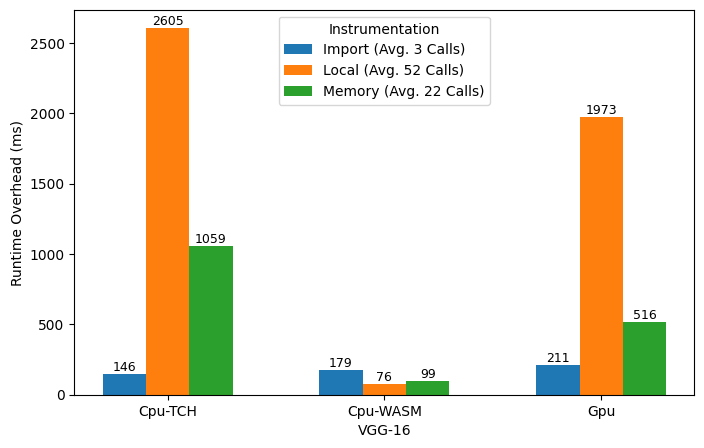

In [8]:
import numpy as np
df = pd.read_csv("../csv-files/combined.csv")

# Resnet
df_resnet = df[df["ml_model"] == "vgg"]

# Rename running modes
df_resnet.loc[:, 'running_mode'] = df_resnet['running_mode'].replace({
    'cpu': 'Cpu-WASM',
    'cputch': 'Cpu-TCH',
    'gpu': 'Gpu'
})


import_att = df_resnet[df_resnet["instrumentation"] == "Import"]["avg_attestations"].mean()
local_att = df_resnet[df_resnet["instrumentation"] == "Local"]["avg_attestations"].mean()
memory_att = df_resnet[df_resnet["instrumentation"] == "Memory"]["avg_attestations"].mean()

df_resnet.loc[:, 'instrumentation'] = df_resnet['instrumentation'].replace({
    'Import': f"Import (Avg. {round(import_att)} Calls)",
    'Local': f"Local (Avg. {round(local_att)} Calls)",
    'Memory': f"Memory (Avg. {round(memory_att)} Calls)",
})

df_resnet_pivot = df_resnet.pivot(index="running_mode", columns="instrumentation", values="avg_overhead_ms")

# Parameters
running_modes = df_resnet_pivot.index
instrumentations = df_resnet_pivot.columns
n_bars = len(instrumentations)
bar_width = 0.2  # width of each bar
x = np.arange(len(running_modes))  # positions for groups

# Plot bars
fig, ax = plt.subplots(figsize=(8,5))

for i, instr in enumerate(instrumentations):
    bars = ax.bar(x + i*bar_width, df_resnet_pivot[instr], width=bar_width, label=instr)
    
    # Add value labels on top of each bar
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height + 0.2,  # position slightly above bar
                f'{round(height)}', ha='center', va='bottom', fontsize=9)

# Labels and ticks
ax.set_xticks(x + bar_width)  # center x-ticks
ax.set_xticklabels(running_modes)
ax.set_ylabel('Runtime Overhead (ms)')
ax.set_xlabel('VGG-16')
ax.legend(title='Instrumentation', loc='upper center')

# Save Plot
diagrams_folder = Path("diagrams")
diagrams_folder.mkdir(parents=True, exist_ok=True)

plt.savefig(diagrams_folder/"overhead-vgg.pdf", bbox_inches="tight", dpi=300)

plt.show()

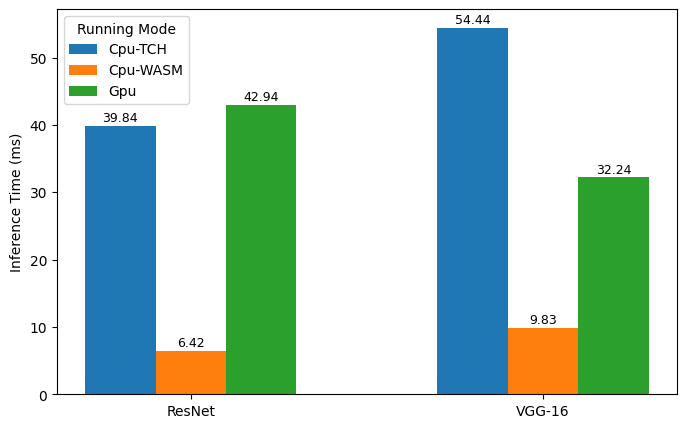

In [11]:
import numpy as np
df = pd.read_csv("../csv-files/combined-inference.csv")
df.loc[:, 'running_mode'] = df['running_mode'].replace({
    'cpu': 'Cpu-WASM',
    'cputch': 'Cpu-TCH',
    'gpu': 'Gpu'
})
df.loc[:, 'ml_model'] = df['ml_model'].replace({
    'resnet': 'ResNet',
    'vgg': 'VGG-16'
})

df_pivot = df.pivot(index="ml_model", columns="running_mode", values="avg_inference_ms")

# Parameters
running_modes = df_pivot.index
instrumentations = df_pivot.columns
n_bars = len(instrumentations)
bar_width = 0.2  # width of each bar
x = np.arange(len(running_modes))  # positions for groups

# Plot bars
fig, ax = plt.subplots(figsize=(8,5))

for i, instr in enumerate(instrumentations):
    bars = ax.bar(x + i*bar_width, df_pivot[instr], width=bar_width, label=instr)
    
    # Add value labels on top of each bar
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height + 0.2,  # position slightly above bar
                f'{height:.2f}', ha='center', va='bottom', fontsize=9)

# Labels and ticks
ax.set_xticks(x + bar_width)  # center x-ticks
ax.set_xticklabels(running_modes)
ax.set_ylabel('Inference Time (ms)')
ax.legend(title='Running Mode', loc='upper left')

# Save Plot
diagrams_folder = Path("diagrams")
diagrams_folder.mkdir(parents=True, exist_ok=True)

plt.savefig(diagrams_folder/"inference-comparison.pdf", bbox_inches="tight", dpi=300)

plt.show()

# IDK

In [ ]:
# Compare Runtime Overhead and Inference time
charts = visualize_runtime_overhead(resnet_dataframes, vgg_dataframes)

runtime_axes = charts["runtime"].plot.bar(rot=0, title="Average Runtime Overhead in 'ms'")
runtime_axes.legend(
    loc="center left", 
    bbox_to_anchor=(1, 0.5),
    frameon=False
)
plt.savefig(diagrams_folder/"runtime_overhead.svg", format="svg", bbox_inches="tight")

inference_axes = charts["inference"].plot.bar(rot=0, title="Average Inference Time in 'ms'")
inference_axes.legend(
    loc="center left", 
    bbox_to_anchor=(1, 0.5),
    frameon=False
)
plt.savefig(diagrams_folder/"inference_overhead.svg", format="svg", bbox_inches="tight")

In [ ]:
# Calculate Model Evaluation Metrics
table_template = {
    "Program": [],
    "Accuracy States": [],
    "Precision States": [],
    "Recall States": [],
    "F1-Score States": [],
    "Accuracy Verdict": [],
    "Precision Verdict": [],
    "Recall Verdict": [],
    "F1-Score Verdict": [],
}

cnn_eval = calculate_model_performance(resnet_dataframes)
cnn_eval_tabel = copy.deepcopy(table_template)
for model, metrics in cnn_eval.items():
    cnn_eval_tabel.setdefault("Program", []).append(model)
    cnn_eval_tabel.get("Accuracy States", []).append(metrics["accuracy_states"])
    cnn_eval_tabel.get("Precision States", []).append(metrics["precision_states"])
    cnn_eval_tabel.get("Recall States", []).append(metrics["recall_states"])
    cnn_eval_tabel.get("F1-Score States", []).append(metrics["f1_score_states"])
    cnn_eval_tabel.get("Accuracy Verdict", []).append(metrics["accuracy_verdict"])
    cnn_eval_tabel.get("Precision Verdict", []).append(metrics["precision_verdict"])
    cnn_eval_tabel.get("Recall Verdict", []).append(metrics["recall_verdict"])
    cnn_eval_tabel.get("F1-Score Verdict", []).append(metrics["f1_score_verdict"])

with open(diagrams_folder/"cnn_model_metrics.txt", "w") as f:
    df = pd.DataFrame(cnn_eval_tabel)
    f.write(df.to_latex())

vgg_eval = calculate_model_performance(vgg_dataframes)
vgg_eval_tabel = copy.deepcopy(table_template)
for model, metrics in vgg_eval.items():
    vgg_eval_tabel.setdefault("Program", []).append(model)
    vgg_eval_tabel.get("Accuracy States", []).append(metrics["accuracy_states"])
    vgg_eval_tabel.get("Precision States", []).append(metrics["precision_states"])
    vgg_eval_tabel.get("Recall States", []).append(metrics["recall_states"])
    vgg_eval_tabel.get("F1-Score States", []).append(metrics["f1_score_states"])
    vgg_eval_tabel.get("Accuracy Verdict", []).append(metrics["accuracy_verdict"])
    vgg_eval_tabel.get("Precision Verdict", []).append(metrics["precision_verdict"])
    vgg_eval_tabel.get("Recall Verdict", []).append(metrics["recall_verdict"])
    vgg_eval_tabel.get("F1-Score Verdict", []).append(metrics["f1_score_verdict"])

with open(diagrams_folder/"vgg_model_metrics.txt", "w") as f:
    df = pd.DataFrame(vgg_eval_tabel)
    f.write(df.to_latex())

In [ ]:
# Calculate average amount of attestated snapshots per run
# df["total_amount_attestations"] = df["amount_good_attestation_results"] + df["amount_bad_attestation_results"]
# average_amount_attestations = df["total_amount_attestations"].mean()
# print(f"Average amount of attestations per run (floored): {int(average_amount_attestations)}")

## Binary Comparison

In [ ]:
# # Combine csv files
# CSV_FILES = Path("../csv-files/binaries")
# COMBINED_FILE = "vgg-gpu.csv"
# CSV_HEADER = "binary,input_type,input_file_name,snapshot_frequency,amount_good_attestation_results,amount_bad_attestation_results,final_attestation_verdict,final_normal_verdict,runtime_normal,amount_instructions_normal,runtime_attestation,amount_instructions_attestation,average_inference_time,final_verdict_fn_calls,average_memory_size"
# skip = ("cpu", "resnet", "memory", "import")
# rows = []
# for file in CSV_FILES.rglob("*"):
#     if file.is_dir() or any(s in str(file) for s in skip):
#         continue
#     print(file)
#     binary = str(file.parent).split("/")[3]
#     with open(file, "r") as f:
#         csv_content = f.read()
#         row = csv_content.splitlines()[1]
    
#     rows.append(f"{binary},{row}")

# with open(COMBINED_FILE, "w") as f:
#     f.write(CSV_HEADER + "\n")
#     f.write("\n".join(rows))

In [ ]:
# Average inference time
import pandas as pd
CSV_FILES = Path("../csv-files/binaries")

dfs = load_csv_files(CSV_FILES)

for name, df in dfs.items():
    average_inferene = df["average_inference_time"].mean()
    average_memory = df["average_memory_size"].mean()
    result_string = f"""
    CSV Name: {name}

    Average Inference Time: {average_inferene:.2f}
    Average Memory Size: {average_memory:.2f}
    """
    print(result_string)

    df_filtered = df[df["average_memory_size"] <= 2.1e7]

    plt.scatter(df_filtered["average_memory_size"], df_filtered["average_inference_time"])
    plt.xlabel("Average Memory Size")
    plt.ylabel("Average Inference Time")
    plt.title(f"Inference Time vs Memory Size ({name})")
    plt.show()